# **BAREC Dataset Preprocessing**

## Project Overview

This notebook focuses on preparing BAREC dataset for Arabic readability classification in Faseeh. It documents the data inspection, cleaning, and preparation steps required before training and evaluating classification models.

### Objectives

- Inspect the dataset structure and identify potential data quality issues.
- Examine missing values, duplicate records, and readability level distributions.
- Apply appropriate preprocessing steps while preserving data integrity.
- Prepare the cleaned data for subsequent classification experiments.

### Workflow

1. Data Loading
2. Data Inspection
3. Data Cleaning
4. Exploratory Data Analysis
5. Final Dataset Preparation

## 1. Data Loading

This section loads the BARQ dataset and prepares the data for inspection and preprocessing.

The dataset loading process should preserve the original data and any predefined splits used in the classification experiments.

The following steps will:
- Load the dataset from its original source.
- Identify the available data splits and features.
- Inspect the dataset dimensions and structure.

In [1]:
from datasets import load_dataset

dataset = load_dataset("CAMeL-Lab/BAREC-Corpus-v1.0")

print(dataset)

README.md:   0%|          | 0.00/6.19k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.9MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/dev-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.37MB            

data/dev-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/54845 [00:00<?, ? examples/s]

Generating dev split:   0%|          | 0/7310 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7286 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['ID', 'Sentence', 'Word_Count', 'Word', 'Lex', 'D3Tok', 'D3Lex', 'Readability_Level', 'Readability_Level_19', 'Readability_Level_7', 'Readability_Level_5', 'Readability_Level_3', 'Annotator', 'Document', 'Source', 'Book', 'Author', 'Domain', 'Text_Class'],
        num_rows: 54845
    })
    dev: Dataset({
        features: ['ID', 'Sentence', 'Word_Count', 'Word', 'Lex', 'D3Tok', 'D3Lex', 'Readability_Level', 'Readability_Level_19', 'Readability_Level_7', 'Readability_Level_5', 'Readability_Level_3', 'Annotator', 'Document', 'Source', 'Book', 'Author', 'Domain', 'Text_Class'],
        num_rows: 7310
    })
    test: Dataset({
        features: ['ID', 'Sentence', 'Word_Count', 'Word', 'Lex', 'D3Tok', 'D3Lex', 'Readability_Level', 'Readability_Level_19', 'Readability_Level_7', 'Readability_Level_5', 'Readability_Level_3', 'Annotator', 'Document', 'Source', 'Book', 'Author', 'Domain', 'Text_Class'],
        num_rows: 7286
    })
})


## 2. Data Inspection

This section examines the structure and size of the BAREC Corpus before preprocessing.

The dataset provides three predefined splits: training, development, and testing. These splits will be preserved throughout the preprocessing workflow.

The inspection focuses on:
- Dataset dimensions and available features.
- Data types and sample records.
- Missing values and duplicate records.
- The distribution of readability labels.

In [2]:
# Display dataset split sizes
for split_name, split_data in dataset.items():
    print(f"{split_name.capitalize()} set: {len(split_data):,} samples")

# Inspect the training set
print("\nFeatures:")
print(dataset["train"].column_names)

print("\nSample record:")
print(dataset["train"][0])

Train set: 54,845 samples
Dev set: 7,310 samples
Test set: 7,286 samples

Features:
['ID', 'Sentence', 'Word_Count', 'Word', 'Lex', 'D3Tok', 'D3Lex', 'Readability_Level', 'Readability_Level_19', 'Readability_Level_7', 'Readability_Level_5', 'Readability_Level_3', 'Annotator', 'Document', 'Source', 'Book', 'Author', 'Domain', 'Text_Class']

Sample record:
{'ID': 10100290001, 'Sentence': 'مجلة كل الأولاد وكل البنات', 'Word_Count': 5, 'Word': 'مجلة كل الأولاد وكل البنات', 'Lex': 'مجلة كل ولد كل بنت', 'D3Tok': 'مجلة كل ال+ أولاد و+ كل ال+ بنات', 'D3Lex': 'مجلة كل ال+ ولد و+ كل ال+ بنت', 'Readability_Level': '7-zay', 'Readability_Level_19': 7, 'Readability_Level_7': 2, 'Readability_Level_5': 1, 'Readability_Level_3': 1, 'Annotator': 'A2', 'Document': 'BAREC_Majed_0413_1987_001.txt', 'Source': 'Majed', 'Book': 'Edition: 413', 'Author': '#', 'Domain': 'Arts & Humanities', 'Text_Class': 'Foundational'}


**Data Inspection Results:**

**Dataset Size**

The BAREC dataset contains 69,441 samples distributed across three predefined splits:

- Train set: 54,845 samples.
- Dev set: 7,310 samples.
- Test set: 7,286 samples.

---

**Dataset Features**

The dataset contains 19 features:

- ID
- Sentence
- Word_Count
- Word
- Lex
- D3Tok
- D3Lex
- Readability_Level
- Readability_Level_19
- Readability_Level_7
- Readability_Level_5
- Readability_Level_3
- Annotator
- Document
- Source
- Book
- Author
- Domain
- Text_Class

---

**Initial Observations**

- The dataset includes multiple readability-level representations: 19, 7, 5, and 3 levels.
- It provides different sentence representations, including tokenized text, lemmas, and morphological segmentation.
- Document and source metadata are available for examining the origin of sentences and understanding the dataset structure.
- The predefined Train, Dev, and Test splits are preserved for subsequent data quality assessment and classification experiments.

## 3. Data Cleaning

This section evaluates the data quality of the BAREC Corpus and identifies potential issues that may affect subsequent classification experiments.

The cleaning process includes:

- **Missing Values:** Identifying missing values across all features.
- **Duplicate Analysis:** Checking for duplicate records using the `ID` field, examining repeated sentences, and verifying the consistency of their readability labels.

All checks are performed independently on the training, development, and testing sets. Records will only be modified or removed when justified by the analysis, while preserving the predefined dataset splits.

### 3.1 Missing Values

This subsection checks all features in the training, development, and testing sets for missing values to assess data completeness before further analysis.

In [6]:
import pandas as pd

for split_name, split_data in dataset.items():
    df = split_data.to_pandas()

    print(f"\n{'=' * 15} {split_name.upper()} {'=' * 15}")
    print(f"Total samples: {len(df):,}")

    missing = df.isnull().sum()
    missing_values = missing[missing > 0]

    print("\nMissing values per feature:")
    if missing_values.empty:
        print("No missing values found.")
    else:
        print(missing_values)


=============== TRAIN ===============
Total samples: 54,845

Missing values per feature:
No missing values found.

=============== DEV ===============
Total samples: 7,310

Missing values per feature:
No missing values found.

=============== TEST ===============
Total samples: 7,286

Missing values per feature:
No missing values found.


**Results:** No missing values were found across any features in the training, development, or testing sets. Therefore, no missing-value treatment was required.

### 3.2 Duplicate Analysis

This subsection examines duplicate records and repeated sentences across the training, development, and testing sets.

The analysis includes:

- **Duplicate IDs:** Checking whether any records share the same unique identifier.
- **Duplicate Sentences:** Identifying repeated sentence text and examining whether repeated sentences have consistent readability labels.

The results are used to assess data quality and document potential duplication. No records are removed during this initial analysis to preserve the original dataset splits for comparison with the published BAREC results.

In [8]:
import pandas as pd

label_columns = [
    "Readability_Level_19",
    "Readability_Level_7",
    "Readability_Level_5"
]

for split_name, split_data in dataset.items():
    df = split_data.to_pandas()

    print(f"\n{'=' * 15} {split_name.upper()} {'=' * 15}")
    print(f"Total samples: {len(df):,}")

    # Check duplicate IDs
    duplicate_ids = df["ID"].duplicated().sum()
    print(f"\nDuplicate IDs: {duplicate_ids:,}")

    # Check repeated sentences
    duplicate_sentences = df["Sentence"].duplicated().sum()
    print(f"Duplicate sentence rows: {duplicate_sentences:,}")

    # Check repeated sentences with conflicting readability labels
    repeated_rows = df[df.duplicated("Sentence", keep=False)]

    for column in label_columns:
        label_counts = (
            repeated_rows.groupby("Sentence")[column]
            .nunique()
        )

        conflicting_labels = (label_counts > 1).sum()

        print(
            f"Repeated sentences with conflicting {column} labels:",
            conflicting_labels
        )


=============== TRAIN ===============
Total samples: 54,845

Duplicate IDs: 0
Duplicate sentence rows: 2,481
Repeated sentences with conflicting Readability_Level_19 labels: 0
Repeated sentences with conflicting Readability_Level_7 labels: 0
Repeated sentences with conflicting Readability_Level_5 labels: 0

=============== DEV ===============
Total samples: 7,310

Duplicate IDs: 0
Duplicate sentence rows: 179
Repeated sentences with conflicting Readability_Level_19 labels: 0
Repeated sentences with conflicting Readability_Level_7 labels: 0
Repeated sentences with conflicting Readability_Level_5 labels: 0

=============== TEST ===============
Total samples: 7,286

Duplicate IDs: 0
Duplicate sentence rows: 213
Repeated sentences with conflicting Readability_Level_19 labels: 0
Repeated sentences with conflicting Readability_Level_7 labels: 0
Repeated sentences with conflicting Readability_Level_5 labels: 0


**Results:**

- **Duplicate IDs:** No duplicate IDs were found in the training, development, or testing sets.
- **Duplicate Sentences:** Repeated sentence rows were identified in all three splits: 2,481 in Train, 179 in Dev, and 213 in Test.
- **Label Consistency:** No conflicting labels were found among repeated sentences for `Readability_Level_19`, `Readability_Level_7`, or `Readability_Level_5` within any individual split.

These findings indicate that repeated sentences within each split have consistent labels across the three examined readability schemes. The original dataset splits remain unchanged to preserve comparability with the published BAREC experiments.

**Original Split Preservation**

The predefined BAREC train, development, and test splits are preserved throughout the baseline experiments to maintain consistency with the original benchmark and support comparison with the published results.

The splits are retained as provided by the dataset authors, who designed the partitioning strategy at the document level and accounted for specific corpus and evaluation requirements.

Exact sentence overlap across splits was identified during data quality assessment and is documented as a potential evaluation consideration. No records are removed or reassigned during the baseline preprocessing stage.

## 4. Exploratory Data Analysis

This section explores the BAREC dataset to understand its readability label distributions and sentence characteristics before classification.

The analysis focuses on:

- **Readability Level Distribution:** Examining the distribution of readability labels across the training, development, and testing sets.
- **Sentence Length Analysis:** Exploring sentence lengths using the `Word_Count` feature.

These analyses help characterize the dataset and identify potential class imbalance and differences in sentence length across readability levels.

### 4.1 Readability Level Distribution

This subsection examines the distribution of readability labels across the training, development, and testing sets using `Readability_Level_19`, `Readability_Level_7`, and `Readability_Level_5`.

The class counts and percentages are calculated separately for each split to identify differences in label distribution and potential class imbalance.

In [10]:
import pandas as pd
from IPython.display import display

label_columns = [
    "Readability_Level_19",
    "Readability_Level_7",
    "Readability_Level_5"
]

for split_name, split_data in dataset.items():
    df = split_data.to_pandas()

    print(f"\n{'=' * 20} {split_name.upper()} {'=' * 20}")

    for column in label_columns:
        counts = df[column].value_counts().sort_index()
        percentages = df[column].value_counts(normalize=True).sort_index() * 100

        summary = pd.DataFrame({
            "Readability Level": counts.index,
            "Count": counts.values,
            "Percentage (%)": percentages.values.round(2)
        })

        print(f"\n{column}")
        display(summary.reset_index(drop=True))


==================== TRAIN ====================

Readability_Level_19


,Readability Level,Count,Percentage (%)
0,1,333,0.61
1,2,333,0.61
2,3,1139,2.08
3,4,587,1.07
4,5,2646,4.82
5,6,1206,2.20
6,7,4152,7.57
7,8,4529,8.26
8,9,1597,2.91
9,10,7741,14.11



Readability_Level_7


,Readability Level,Count,Percentage (%)
0,1,2392,4.36
1,2,8004,14.59
2,3,6126,11.17
3,4,11782,21.48
4,5,14570,26.57
5,6,10589,19.31
6,7,1382,2.52



Readability_Level_5


...

,Readability Level,Count,Percentage (%)
0,1,32,0.44
1,2,36,0.49
2,3,141,1.94
3,4,86,1.18
4,5,380,5.22
5,6,139,1.91
6,7,585,8.03
7,8,541,7.43
8,9,190,2.61
9,10,1010,13.86



Readability_Level_7


,Readability Level,Count,Percentage (%)
0,1,295,4.05
1,2,1104,15.15
2,3,731,10.03
3,4,1474,20.23
4,5,2100,28.82
5,6,1315,18.05
6,7,267,3.66



Readability_Level_5


,Readability Level,Count,Percentage (%)
0,1,1399,19.20
1,2,2205,30.26
2,3,2100,28.82
3,4,1315,18.05
4,5,267,3.66


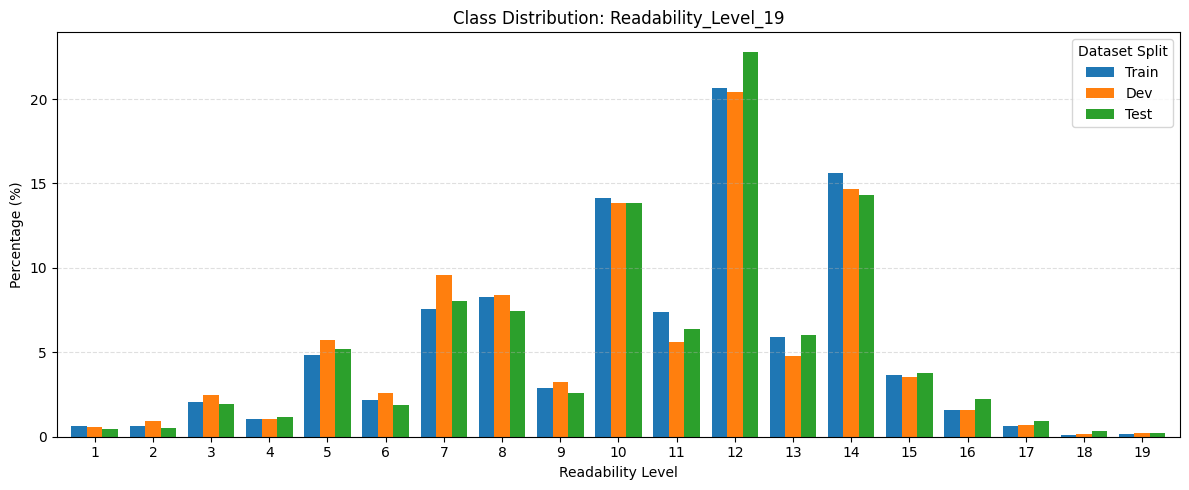

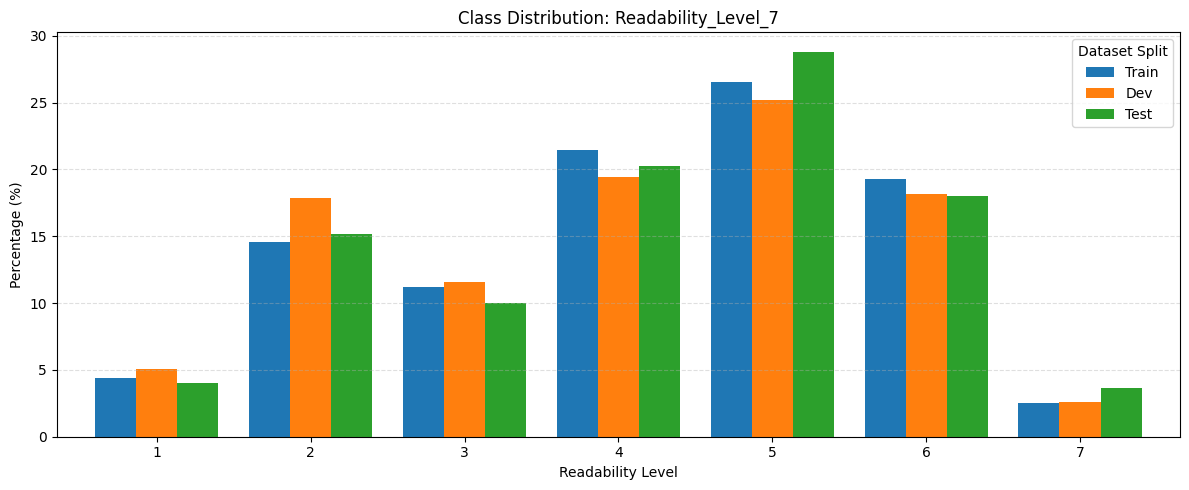

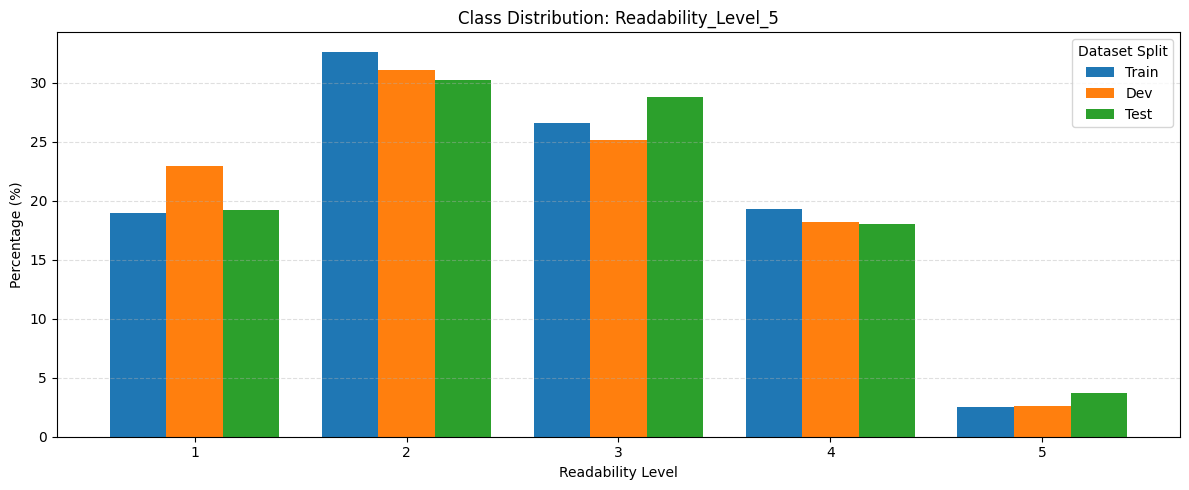

In [11]:

import pandas as pd
import matplotlib.pyplot as plt

label_columns = [
    "Readability_Level_19",
    "Readability_Level_7",
    "Readability_Level_5"
]

for column in label_columns:
    distributions = {}

    for split_name, split_data in dataset.items():
        df = split_data.to_pandas()

        percentages = (
            df[column]
            .value_counts(normalize=True)
            .sort_index() * 100
        )

        distributions[split_name.title()] = percentages

    plot_df = pd.DataFrame(distributions).fillna(0)

    ax = plot_df.plot(
        kind="bar",
        figsize=(12, 5),
        width=0.8
    )

    ax.set_title(f"Class Distribution: {column}")
    ax.set_xlabel("Readability Level")
    ax.set_ylabel("Percentage (%)")
    ax.legend(title="Dataset Split")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


**Results:**

- **19-Level Classification:** The label distribution is imbalanced across all three splits. Levels 12, 14, and 10 are among the most frequent classes, while levels 18 and 19 are the least represented. Level 12 accounts for 20.64% of Train, 20.40% of Dev, and 22.81% of Test.

- **7-Level Classification:** Level 5 is the most frequent class across all splits, representing 26.57% of Train, 25.17% of Dev, and 28.82% of Test. Level 7 is the least represented class in all three splits.

- **5-Level Classification:** Level 2 is the most frequent class across all splits, while Level 5 is the least represented. Level 2 accounts for 32.65% of Train, 31.05% of Dev, and 30.26% of Test.

- **Split Comparison:** The overall label distributions are broadly similar across Train, Dev, and Test, although some differences exist in individual class proportions.

These results indicate class imbalance in all three classification schemes. This imbalance should be considered when evaluating model performance, particularly for underrepresented readability levels.


### 4.2 Class Imbalance Analysis and Merged-Level Strategy

The exploratory analysis revealed class imbalance in the five-level readability classification scheme, particularly in Level 5, which represents a relatively small proportion of the training data.

To investigate a possible solution, Levels 4 and 5 are merged into a single class, reducing the classification scheme from five levels to four. This strategy aims to reduce the underrepresentation of the minority class and examine how merging adjacent readability levels affects the class distribution.

The original dataset and its labels are preserved. The merged-level dataset is created as a separate version and is used only in selected classification experiments. The class distributions before and after merging are compared to evaluate the effect of this strategy.



=============== TRAIN ===============


,Original Count,Original (%),Merged Count,Merged (%)
Readability Level,,,,
1,10396,18.96,10396.0,18.96
2,17908,32.65,17908.0,32.65
3,14570,26.57,14570.0,26.57
4,10589,19.31,11971.0,21.83
5,1382,2.52,0.0,0.00



=============== DEV ===============


,Original Count,Original (%),Merged Count,Merged (%)
Readability Level,,,,
1,1679,22.97,1679.0,22.97
2,2270,31.05,2270.0,31.05
3,1840,25.17,1840.0,25.17
4,1330,18.19,1521.0,20.81
5,191,2.61,0.0,0.00



=============== TEST ===============


,Original Count,Original (%),Merged Count,Merged (%)
Readability Level,,,,
1,1399,19.20,1399.0,19.20
2,2205,30.26,2205.0,30.26
3,2100,28.82,2100.0,28.82
4,1315,18.05,1582.0,21.71
5,267,3.66,0.0,0.00


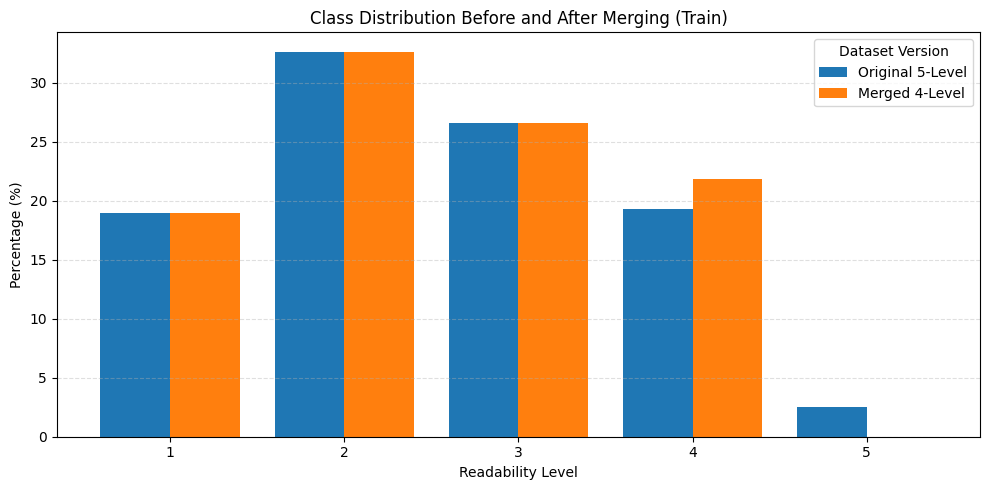

In [14]:

import pandas as pd
import matplotlib.pyplot as plt

# Create independent copies of the original splits
merged_datasets = {}
comparison_results = {}

for split_name, split_data in dataset.items():
    df = split_data.to_pandas().copy()

    # Preserve the original labels and create a separate 4-level target
    df["Readability_Level_4"] = (
        df["Readability_Level_5"].replace({5: 4})
    )

    merged_datasets[split_name] = df

    # Compare class counts before and after merging
    original_counts = (
        df["Readability_Level_5"]
        .value_counts()
        .sort_index()
    )

    merged_counts = (
        df["Readability_Level_4"]
        .value_counts()
        .sort_index()
    )

    comparison = pd.DataFrame({
        "Original Count": original_counts,
        "Original (%)": (
            original_counts / len(df) * 100
        ),
        "Merged Count": merged_counts,
        "Merged (%)": (
            merged_counts / len(df) * 100
        )
    }).fillna(0)

    comparison.index.name = "Readability Level"
    comparison_results[split_name] = comparison

    print(f"\n{'=' * 15} {split_name.upper()} {'=' * 15}")
    display(comparison.round(2))

# Visualize the distribution before and after merging in Train
train_comparison = comparison_results["train"]

plot_df = pd.DataFrame({
    "Original 5-Level": train_comparison["Original (%)"],
    "Merged 4-Level": train_comparison["Merged (%)"]
})

plot_df.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.8
)

plt.title("Class Distribution Before and After Merging (Train)")
plt.xlabel("Readability Level")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Dataset Version")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()



**Results:**

- **Train Set:** Merging Levels 4 and 5 increased the proportion of Level 4 from 19.31% to 21.83%.
- **Dev Set:** The proportion of Level 4 increased from 18.19% to 20.81%.
- **Test Set:** The proportion of Level 4 increased from 18.05% to 21.71%.
- **Effect on Class Distribution:** The merged class contains all samples previously assigned to Levels 4 and 5. The counts and proportions of Levels 1, 2, and 3 remain unchanged.
- **Overall Observation:** Merging the two levels reduces the classification task from five classes to four and increases the representation of the merged class. However, the resulting distribution is not perfectly balanced.

The merged-level dataset is retained separately from the original dataset and will be used only in selected classification experiments.



### 4.3 Sentence Length Analysis

This subsection examines sentence lengths using the `Word_Count` feature to understand how sentence length varies across readability levels.

The analysis includes:

- **Descriptive Statistics:** Calculating the mean, median, minimum, and maximum sentence lengths.
- **Sentence Length Distribution:** Visualizing the distribution of sentence lengths across the dataset.
- **Length by Readability Level:** Comparing average sentence lengths across readability levels to identify potential patterns.


Sentence Length Statistics (Train)


,Value
Number of sentences,54845.000000
Mean,15.183572
Median,12.000000
Minimum,1.000000
Maximum,163.000000


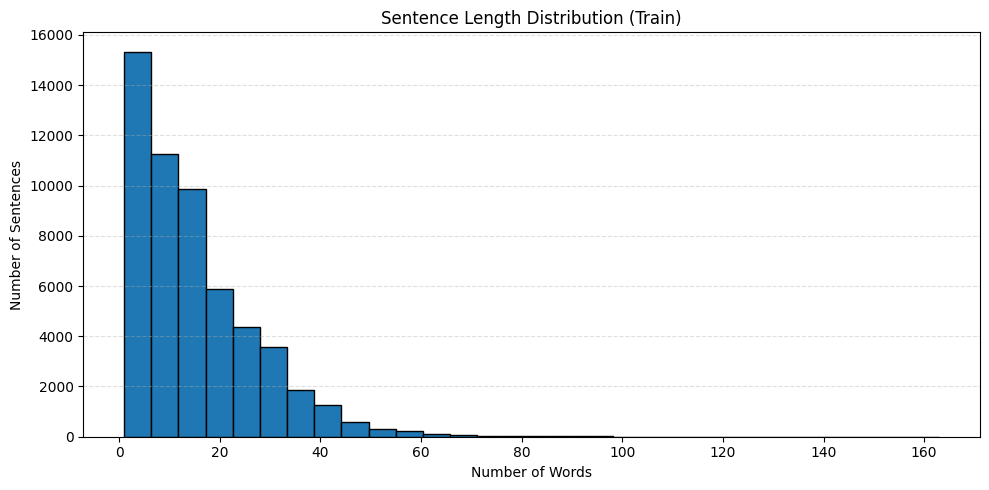

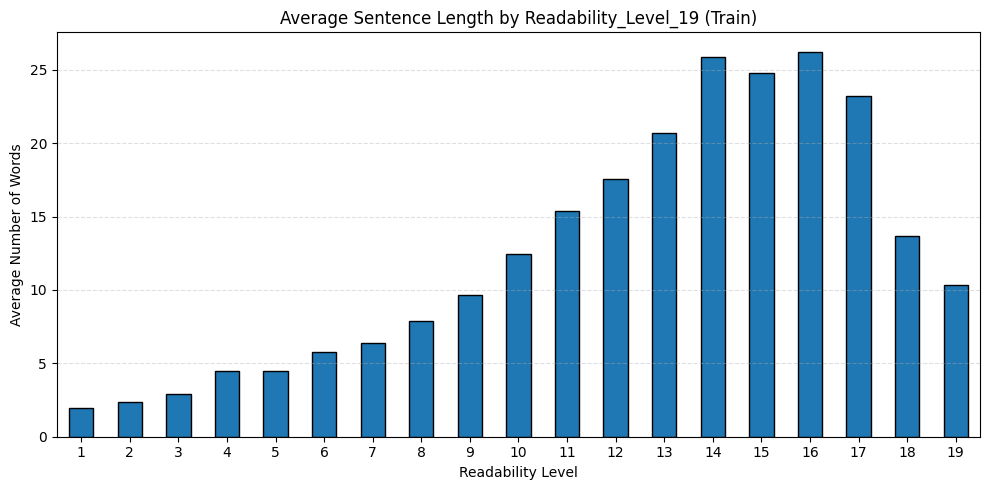

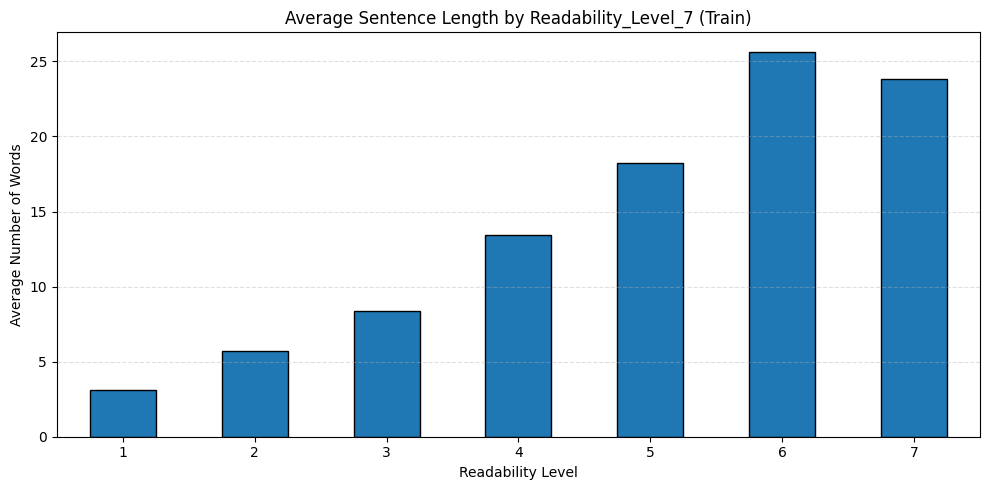

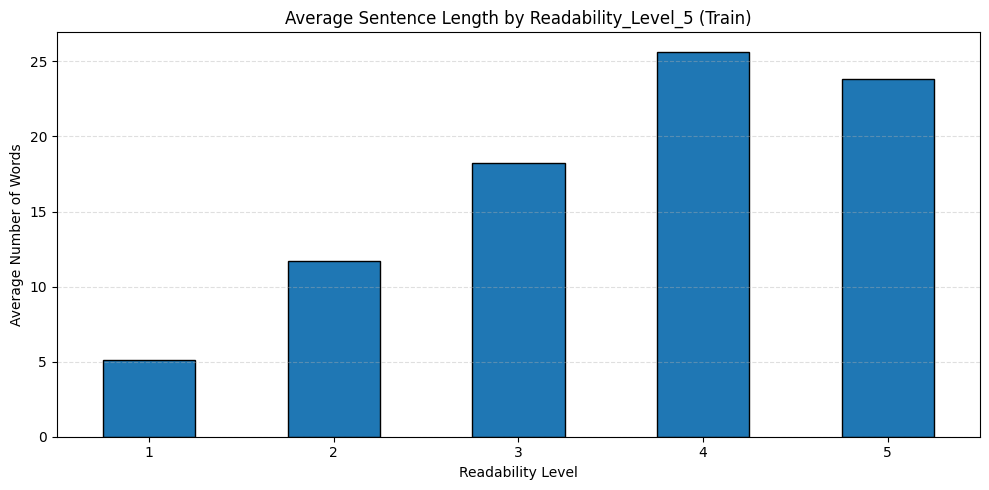

In [12]:

import pandas as pd
import matplotlib.pyplot as plt

# Use the training split for exploratory analysis
train_df = dataset["train"].to_pandas()

# Ensure Word_Count is numeric
train_df["Word_Count"] = pd.to_numeric(
    train_df["Word_Count"], errors="coerce"
)

word_counts = train_df["Word_Count"].dropna()

# 1. Descriptive statistics
print("Sentence Length Statistics (Train)")
display(
    word_counts.describe()[
        ["count", "mean", "50%", "min", "max"]
    ].rename({
        "count": "Number of sentences",
        "mean": "Mean",
        "50%": "Median",
        "min": "Minimum",
        "max": "Maximum"
    }).to_frame("Value")
)

# 2. Sentence length distribution
plt.figure(figsize=(10, 5))
plt.hist(word_counts, bins=30, edgecolor="black")
plt.title("Sentence Length Distribution (Train)")
plt.xlabel("Number of Words")
plt.ylabel("Number of Sentences")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# 3. Average sentence length by readability level
label_columns = [
    "Readability_Level_19",
    "Readability_Level_7",
    "Readability_Level_5"
]

for column in label_columns:
    avg_lengths = (
        train_df.groupby(column)["Word_Count"]
        .mean()
        .sort_index()
    )

    plt.figure(figsize=(10, 5))
    avg_lengths.plot(kind="bar", edgecolor="black")

    plt.title(f"Average Sentence Length by {column} (Train)")
    plt.xlabel("Readability Level")
    plt.ylabel("Average Number of Words")
    plt.xticks(rotation=0)
    plt.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()



**Results:**

- **Sentence Length Statistics:** The training set contains 54,845 sentences. The mean sentence length is 15.18 words, while the median is 12 words. Sentence lengths range from 1 to 163 words.

- **Sentence Length Distribution:** The distribution is right-skewed, indicating that shorter sentences are more common than longer sentences. A small number of very long sentences extend the distribution toward higher word counts.

- **19-Level Classification:** Average sentence length generally increases across the lower and middle readability levels, reaching its highest value around Level 16, before decreasing at higher levels.

- **7-Level Classification:** Average sentence length increases from Level 1 to Level 6, then decreases slightly at Level 7.

- **5-Level Classification:** Average sentence length increases from Level 1 to Level 4, then decreases at Level 5.

Overall, sentence length varies across readability levels, suggesting that `Word_Count` may provide useful information for readability classification. However, sentence length alone does not fully determine readability.



## 5. Final Dataset Preparation

Two separate versions of the BAREC dataset are prepared for subsequent classification experiments.

- **Original Dataset:** Preserves the original readability labels and the predefined Train, Dev, and Test splits. It is used for experiments with the original classification schemes.
- **Merged-Level Dataset:** Adds a new `Readability_Level_4` target by merging Levels 4 and 5 of `Readability_Level_5` into a single Level 4. This version is used only in selected four-level classification experiments.

Both versions retain all original records and preserve the predefined dataset splits. The original dataset remains unchanged, allowing the two versions to be used independently and their experimental results to be compared.


In [15]:

import os
import zipfile
import pandas as pd
from google.colab import files

# Output directories
base_dir = "/content/BAREC_prepared_datasets"
original_dir = os.path.join(base_dir, "original")
merged_dir = os.path.join(base_dir, "merged_4_level")

os.makedirs(original_dir, exist_ok=True)
os.makedirs(merged_dir, exist_ok=True)

for split_name, split_data in dataset.items():
    # 1. Save the original dataset without modifications
    original_df = split_data.to_pandas()

    original_path = os.path.join(
        original_dir, f"{split_name}.csv"
    )
    original_df.to_csv(
        original_path, index=False, encoding="utf-8-sig"
    )

    # 2. Create and save a separate merged-level version
    merged_df = original_df.copy()

    merged_df["Readability_Level_4"] = (
        merged_df["Readability_Level_5"].replace({5: 4})
    )

    merged_path = os.path.join(
        merged_dir, f"{split_name}.csv"
    )
    merged_df.to_csv(
        merged_path, index=False, encoding="utf-8-sig"
    )

# Create a ZIP file containing both dataset versions
zip_path = "/content/BAREC_prepared_datasets.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for folder, _, filenames in os.walk(base_dir):
        for filename in filenames:
            file_path = os.path.join(folder, filename)
            arcname = os.path.relpath(file_path, base_dir)
            zipf.write(file_path, arcname)

print("Dataset versions saved successfully.")
print("\nOriginal dataset:")
print(f"Train: {len(dataset['train']):,}")
print(f"Dev:   {len(dataset['dev']):,}")
print(f"Test:  {len(dataset['test']):,}")

print("\nMerged-level dataset:")
print(f"Train: {len(dataset['train']):,}")
print(f"Dev:   {len(dataset['dev']):,}")
print(f"Test:  {len(dataset['test']):,}")

print("\nZIP file:", zip_path)

# Download the ZIP file to your computer
files.download(zip_path)


Dataset versions saved successfully.

Original dataset:
Train: 54,845
Dev:   7,310
Test:  7,286

Merged-level dataset:
Train: 54,845
Dev:   7,310
Test:  7,286

ZIP file: /content/BAREC_prepared_datasets.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>